In [169]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pt
from statsmodels.tsa.stattools import adfuller
from pandas.plotting import autocorrelation_plot
from pmdarima import auto_arima
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# Understanding the data

In [170]:
df=pd.read_csv('SELMart.csv')
df.head()

,Month,Revenue
0,2022-01,266.0
1,2022-02,145.9
2,2022-03,183.1
3,2022-04,119.3
4,2022-05,180.3


In [171]:
df.columns=['Month','Sales']

In [172]:
df.head()

,Month,Sales
0,2022-01,266.0
1,2022-02,145.9
2,2022-03,183.1
3,2022-04,119.3
4,2022-05,180.3


In [173]:
df['Month']=pd.to_datetime(df['Month'])

In [174]:
df.set_index('Month')

,Sales
Month,
2022-01-01,266.0
2022-02-01,145.9
2022-03-01,183.1
2022-04-01,119.3
2022-05-01,180.3
2022-06-01,168.5
2022-07-01,231.8
2022-08-01,224.5
2022-09-01,192.8


In [175]:
df.dtypes

Month    datetime64[ns]
Sales           float64
dtype: object

In [176]:
df.shape

(36, 2)

In [177]:
df.columns

Index(['Month', 'Sales'], dtype='object')

In [178]:
df.isna().sum()

Month    0
Sales    0
dtype: int64

In [179]:
df.duplicated().sum()

np.int64(0)

In [180]:
df.describe()

,Month,Sales
count,36,36.000000
mean,2023-06-16 18:40:00,312.600000
min,2022-01-01 00:00:00,119.300000
25%,2022-09-23 12:00:00,192.450000
50%,2023-06-16 00:00:00,280.150000
75%,2024-03-08 18:00:00,411.100000
max,2024-12-01 00:00:00,682.000000
std,NaN,148.937164


In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Month   36 non-null     datetime64[ns]
 1   Sales   36 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 708.0 bytes


# Visualize the data

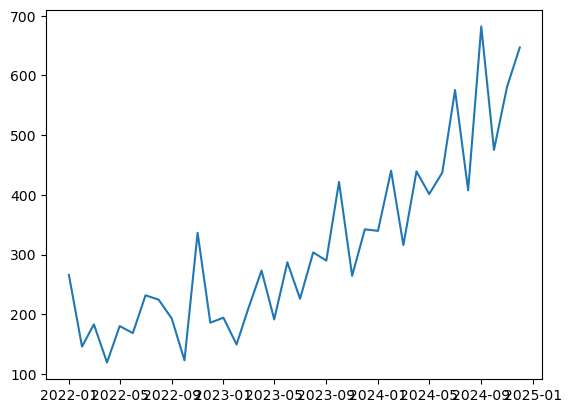

In [182]:
pt.plot(df['Month'],df['Sales'])

# Check for stationarity

In [183]:
def adfuller_test(Sales):
    results=adfuller(Sales)
    labels=['ADF Test Statistics','p-value','#lags Used','No of observations Used']
    for value,label in zip(results,labels):
        print(label+':'+str(value))
    if results[1]<=.5:
        print('stationary')
    else:
        print('non-stationary')

In [184]:
adfuller_test(df['Sales'])

ADF Test Statistics:3.0601420836411792
p-value:1.0
#lags Used:10
No of observations Used:25
non-stationary


In [185]:
df['first sales difference']=df['Sales']-df['Sales'].shift(1)

In [186]:
adfuller_test(df['first sales difference'].dropna())

ADF Test Statistics:-7.249074055553854
p-value:1.7998574141687034e-10
#lags Used:1
No of observations Used:33
stationary


In [187]:
df.head()

,Month,Sales,first sales difference
0,2022-01-01,266.0,NaN
1,2022-02-01,145.9,-120.1
2,2022-03-01,183.1,37.2
3,2022-04-01,119.3,-63.8
4,2022-05-01,180.3,61.0


In [188]:
clean_data=df['first sales difference'].dropna()

In [189]:
model=auto_arima(clean_data,seasonal=True,m=12,p=0,q=0,max_p=5,max_q=5)

In [190]:
print(model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                   35
Model:             SARIMAX(1, 0, 1)x(0, 0, 1, 12)   Log Likelihood                -194.763
Date:                            Thu, 23 Jul 2026   AIC                            399.526
Time:                                    01:38:47   BIC                            407.302
Sample:                                         0   HQIC                           402.210
                                             - 35                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     19.8012      4.268      4.640      0.000      11.436      28.166
ar.L1         -0.5468      0.184   

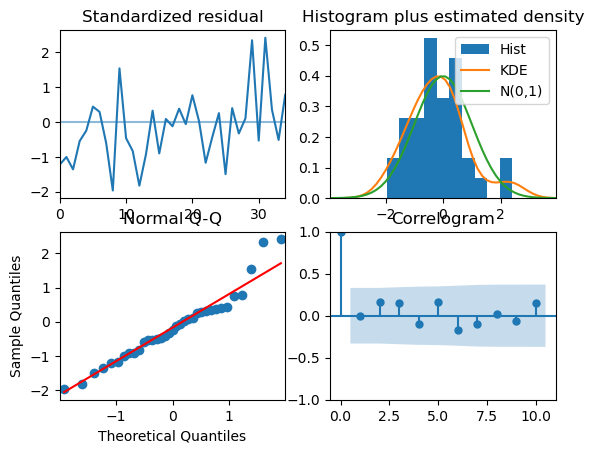

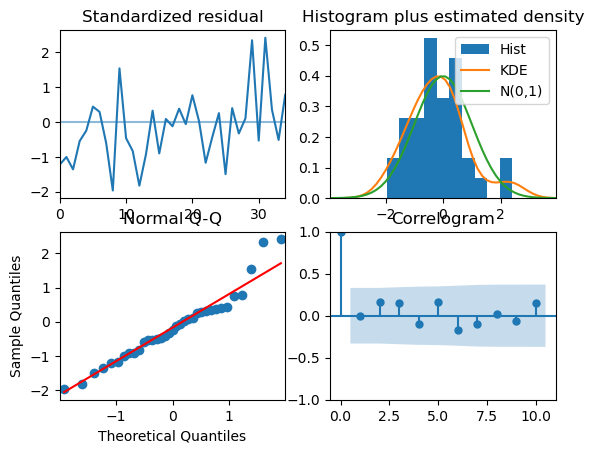

In [191]:
model.plot_diagnostics()

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

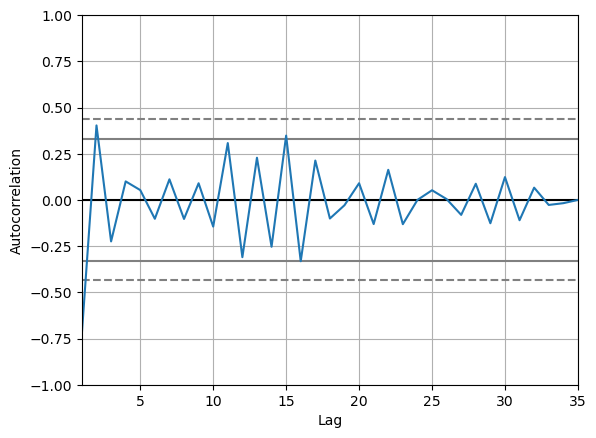

In [192]:
autocorrelation_plot(df['first sales difference'].dropna())

In [193]:
AIC=model.aic().round(3)
BIC=model.bic().round(3)
print('AIC:',AIC)
print('BIC:',BIC)

AIC: 399.526
BIC: 407.302


In [194]:
# forecast
forecast,conf_int=model.predict(n_periods=12,return_conf_int=True,alpha=.05)


C:\Users\PATHWAY\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\PATHWAY\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


In [195]:
print('forecast( first sales difference)')
print(forecast)
print('n\conf_intervals')
print(conf_int)

forecast( first sales difference)
35    -42.410196
36     24.004419
37     70.395771
38    -62.458969
39     74.428711
40    -31.146993
41    -53.105857
42    114.131866
43   -147.368662
44    132.227030
45    -25.401610
46     -6.918325
dtype: float64
n\conf_intervals
[[-154.23380466   69.4134128 ]
 [-135.27176343  183.28060153]
 [-100.23504785  241.02658925]
 [-236.34087582  111.42293878]
 [-100.41348878  249.27091062]
 [-206.27515248  143.98116584]
 [-228.31894121  122.10722797]
 [ -61.10497881  289.36871073]
 [-322.60717691   27.86985378]
 [ -42.99381264  307.44787292]
 [-200.55637681  149.75315655]
 [-181.84983709  168.01318695]]


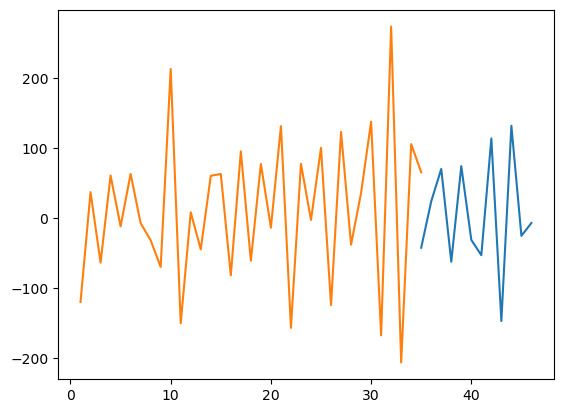

In [196]:
pt.plot(forecast)
pt.plot(clean_data)

# skipping stationarity and using the arima model

If you do not check the stationarity, the auto_arima model can automatically do the differencing for you.compare in the model summary. I used the SALES COLUMN instead of the FIRST SALES DIFFERENCE

In [ ]:
mod=auto_arima(df['Sales'],p=0,q=0,max_p=5,max_q=5,m=12)

In [ ]:
mod.summary()